# Lab E - Q-learning (reinforcement learning)
An agent learns action values `Q(s,a)` by trial and error. Update rule:

`Q(s,a) <- Q(s,a) + alpha * [ r + gamma * max_a' Q(s',a') - Q(s,a) ]`

Environment: 4x4 gridworld, start top-left, goal bottom-right (+1), two pits (-1), small step cost (-0.01). Deterministic moves; hitting a wall leaves you in place.

In [1]:
import sys; sys.path.insert(0, '../../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
np.set_printoptions(precision=3, suppress=True); pd.set_option('display.width', 160)
N = 4; START, GOAL, PITS = (0, 0), (3, 3), {(1, 1), (2, 3)}; ACTIONS = ['up', 'down', 'left', 'right']; MOVES = [(-1, 0), (1, 0), (0, -1), (0, 1)]
def step(s, a):
    r, c = s; dr, dc = MOVES[a]; n = (min(max(r + dr, 0), N - 1), min(max(c + dc, 0), N - 1))
    if n == GOAL: return n, 1.0, True
    if n in PITS: return n, -1.0, True
    return n, -0.01, False

alpha, gamma, episodes = 0.1, 0.95, 3000
rng = np.random.default_rng(0); Q = np.zeros((N, N, 4)); returns = []
for ep in range(episodes):
    eps = max(0.05, 1 - ep / (0.6 * episodes)); s, done, G = START, False, 0
    for t in range(100):
        a = rng.integers(4) if rng.random() < eps else int(np.argmax(Q[s]))
        n, r, done = step(s, a)
        Q[s][a] += alpha * (r + gamma * (0 if done else Q[n].max()) - Q[s][a])   # the Q-learning update
        s, G = n, G + r
        if done: break
    returns.append(G)
print('trained for', episodes, 'episodes')

trained for 3000 episodes


## Learning curve (average return per 100 episodes)

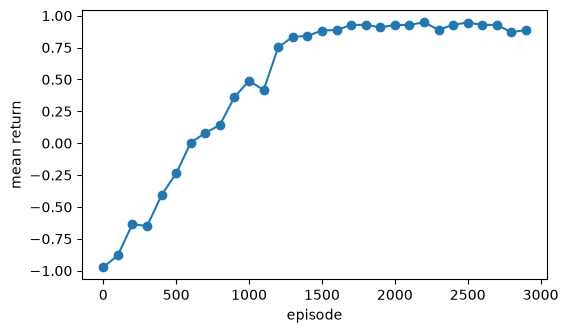

mean return first 100 episodes: -0.97, last 100: 0.89


In [2]:
avg = np.array(returns).reshape(-1, 100).mean(axis=1); plt.figure(figsize=(6, 3.5)); plt.plot(np.arange(len(avg)) * 100, avg, marker='o'); plt.xlabel('episode'); plt.ylabel('mean return'); plt.show()
print('mean return first 100 episodes: %.2f, last 100: %.2f' % (np.mean(returns[:100]), np.mean(returns[-100:])))

## Learned greedy policy (arrows) and state values

In [3]:
arrow = ['^', 'v', '<', '>']; grid = [[('G' if (r, c) == GOAL else 'X' if (r, c) in PITS else arrow[int(np.argmax(Q[r, c]))]) for c in range(N)] for r in range(N)]
print('\n'.join(' '.join(row) for row in grid)); print(); print('V(s) = max_a Q(s,a):'); print(Q.max(axis=2).round(2))

v > v <
v X v <
v v v X
> > > G

V(s) = max_a Q(s,a):
[[0.73 0.78 0.83 0.72]
 [0.78 0.   0.88 0.78]
 [0.83 0.88 0.94 0.  ]
 [0.88 0.94 1.   0.  ]]


## One Q-update worked by hand
Take state (3,2) and action 'right' (into the goal at (3,3)): r=+1, terminal so the future term is 0. From Q=0: new Q = 0 + 0.1*(1 + 0 - 0) = 0.1. Check with code:

In [4]:
Qh = np.zeros((N, N, 4)); s = (3, 2); a = 3; n, r, done = step(s, a)
new = Qh[s][a] + alpha * (r + gamma * (0 if done else Qh[n].max()) - Qh[s][a])
print(f'state {s}, action {ACTIONS[a]}, next {n}, reward {r}, terminal {done} -> Q_new = 0 + {alpha}*({r} + 0 - 0) = {new}')

state (3, 2), action right, next (3, 3), reward 1.0, terminal True -> Q_new = 0 + 0.1*(1.0 + 0 - 0) = 0.1


**Exploration vs. exploitation:** epsilon-greedy picks a random action with probability epsilon (decayed from 1 to 0.05) so the agent first explores, then exploits what it learned. **Off-policy:** the update uses max over next actions, not the action actually taken.